<a href="https://colab.research.google.com/github/bimaadiwijaya8/-ML_05_Bima-Adiwijaya/blob/main/JS10/JS10-Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS10 — Artificial Neural Network (Klasifikasi MNIST)

Pada praktikum ini, kita membangun dan mengeksplorasi model **Artificial Neural Network (ANN)** berbasis **TensorFlow (`tf.keras`)** untuk mengklasifikasikan citra tulisan tangan angka `0–9` pada dataset **MNIST**.

Aspek yang dieksplorasi:
1. **Pra-pengolahan data** (normalisasi, *train/val/test split*, augmentasi)
2. **Pemilihan fitur** (*raw 784 pixels* vs reduksi dimensi/fitur PCA)
3. **Arsitektur ANN** (kedalaman & lebar *hidden layer*, *Dropout*, *BatchNormalization*)
4. **Fungsi aktivasi** (`ReLU`, `GELU`, `LeakyReLU`, `ELU`)

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


## 1. Eksplorasi Pra-Pengolahan Data

Dataset MNIST terdiri dari 60.000 data latih dan 10.000 data uji berukuran `28x28` piksel (*grayscale*).
Di sini kita membandingkan dua skema pra-pengolahan:
- **Prep A (`norm_only`)**: Normalisasi nilai piksel dari `[0, 255]` ke `[0.0, 1.0]` (`float32`).
- **Prep B (`norm_standard`)**: Normalisasi `[0.0, 1.0]` lalu distandarisasi berdasarkan mean dan standar deviasi data latih.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (50000, 784), Val shape: (10000, 784), Test shape: (10000, 784)


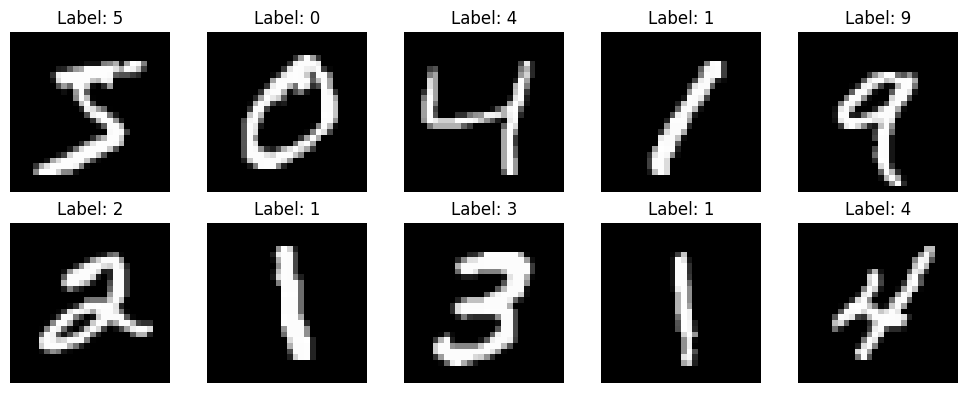

In [2]:
(x_train_full, y_train_full), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

# Pisahkan 10.000 data latih terakhir sebagai validation set (50k train, 10k val, 10k test)
x_train_raw, x_val_raw = x_train_full[:-10000], x_train_full[-10000:]
y_train, y_val = y_train_full[:-10000], y_train_full[-10000:]

# Skema A: Normalisasi [0, 1] dan flatten (N, 784)
x_train_norm = (x_train_raw.astype("float32") / 255.0).reshape(-1, 28 * 28)
x_val_norm = (x_val_raw.astype("float32") / 255.0).reshape(-1, 28 * 28)
x_test_norm = (x_test_raw.astype("float32") / 255.0).reshape(-1, 28 * 28)

# Skema B: Standarisasi (z-score) setelah normalisasi [0, 1]
mean = x_train_norm.mean(axis=0, keepdims=True)
std = x_train_norm.std(axis=0, keepdims=True) + 1e-7

x_train_std = (x_train_norm - mean) / std
x_val_std = (x_val_norm - mean) / std
x_test_std = (x_test_norm - mean) / std

print(f"Train shape: {x_train_norm.shape}, Val shape: {x_val_norm.shape}, Test shape: {x_test_norm.shape}")

# Visualisasi beberapa sampel citra
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_raw[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Eksplorasi Pemilihan Fitur

Citra `28x28` yang di-*flatten* memiliki 784 fitur piksel. Kita membandingkan:
- **Semua fitur piksel (`784` fitur)**
- **Reduksi fitur dengan PCA (`128` komponen utama)** yang mempertahankan sebagian besar variansi citra dengan dimensi jauh lebih ringkas.

In [3]:
n_components = 128
pca = PCA(n_components=n_components, random_state=SEED)

x_train_pca = pca.fit_transform(x_train_std)
x_val_pca = pca.transform(x_val_std)
x_test_pca = pca.transform(x_test_std)

explained_var = np.sum(pca.explained_variance_ratio_) * 100
print(f"Variansi dijelaskan oleh {n_components} komponen PCA: {explained_var:.2f}%")

Variansi dijelaskan oleh 128 komponen PCA: 76.71%


## 3 & 4. Eksplorasi Arsitektur ANN dan Fungsi Aktivasi

Kita membangun fungsi `build_ann_model(...)` yang fleksibel untuk menguji berbagai kombinasi:
- **Arsitektur**:
  - `shallow`: `[128, 64]`
  - `deep_reg`: `[512, 256, 128]` dengan `BatchNormalization` dan `Dropout`
- **Fungsi Aktivasi**: `'relu'`, `'gelu'`, `'elu'`, atau `'leaky_relu'`

In [4]:
def get_activation_layer(activation_name: str):
    if activation_name == "leaky_relu":
        return layers.LeakyReLU(negative_slope=0.1)
    return layers.Activation(activation_name)


def build_ann_model(
    input_dim: int,
    hidden_units: list[int],
    activation: str = "relu",
    dropout_rate: float = 0.2,
    use_batchnorm: bool = True,
    learning_rate: float = 1e-3,
) -> keras.Model:
    inputs = keras.Input(shape=(input_dim,))
    x = inputs

    for units in hidden_units:
        x = layers.Dense(units, use_bias=not use_batchnorm)(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        x = get_activation_layer(activation)(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name=f"ANN_{activation}_{input_dim}d")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def train_and_evaluate(
    model: keras.Model,
    X_tr, y_tr,
    X_va, y_va,
    X_te, y_te,
    epochs: int = 15,
    batch_size: int = 128,
):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=4,
            restore_best_weights=True,
        )
    ]
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0,
    )
    test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
    val_acc = max(history.history["val_accuracy"])
    return history, val_acc, test_acc, test_loss

## 5. Menjalankan Skenario Eksperimen

Kita menguji beberapa konfigurasi pra-pengolahan, fitur, arsitektur, dan fungsi aktivasi secara sistematis, lalu membandingkan akurasi validasi dan akurasi data uji.

In [5]:
experiments = [
    {
        "name": "Exp1_Norm_ReLU_Shallow",
        "data": (x_train_norm, x_val_norm, x_test_norm),
        "hidden": [128, 64],
        "activation": "relu",
        "dropout": 0.1,
        "bn": False,
    },
    {
        "name": "Exp2_Std_ReLU_DeepBN",
        "data": (x_train_std, x_val_std, x_test_std),
        "hidden": [512, 256, 128],
        "activation": "relu",
        "dropout": 0.25,
        "bn": True,
    },
    {
        "name": "Exp3_Std_GELU_DeepBN",
        "data": (x_train_std, x_val_std, x_test_std),
        "hidden": [512, 256, 128],
        "activation": "gelu",
        "dropout": 0.25,
        "bn": True,
    },
    {
        "name": "Exp4_Std_LeakyReLU_DeepBN",
        "data": (x_train_std, x_val_std, x_test_std),
        "hidden": [512, 256, 128],
        "activation": "leaky_relu",
        "dropout": 0.25,
        "bn": True,
    },
    {
        "name": "Exp5_PCA128_GELU_DeepBN",
        "data": (x_train_pca, x_val_pca, x_test_pca),
        "hidden": [512, 256, 128],
        "activation": "gelu",
        "dropout": 0.25,
        "bn": True,
    },
]

results = []
trained_models = {}

for exp in experiments:
    X_tr, X_va, X_te = exp["data"]
    model = build_ann_model(
        input_dim=X_tr.shape[1],
        hidden_units=exp["hidden"],
        activation=exp["activation"],
        dropout_rate=exp["dropout"],
        use_batchnorm=exp["bn"],
    )
    hist, val_acc, test_acc, test_loss = train_and_evaluate(
        model, X_tr, y_train, X_va, y_val, X_te, y_test,
        epochs=15, batch_size=128
    )
    trained_models[exp["name"]] = (model, X_te, hist)
    results.append({
        "Eksperimen": exp["name"],
        "Fitur": X_tr.shape[1],
        "Arsitektur": str(exp["hidden"]),
        "Aktivasi": exp["activation"],
        "Best Val Acc": round(val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
    })
    print(f"{exp['name']:28s} | Val Acc: {val_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")

df_results = pd.DataFrame(results).sort_values(by="Test Acc (%)", ascending=False)
display(df_results)

Exp1_Norm_ReLU_Shallow       | Val Acc: 98.05% | Test Acc: 98.00%
Exp2_Std_ReLU_DeepBN         | Val Acc: 97.90% | Test Acc: 97.76%
Exp3_Std_GELU_DeepBN         | Val Acc: 98.27% | Test Acc: 97.81%
Exp4_Std_LeakyReLU_DeepBN    | Val Acc: 97.99% | Test Acc: 97.86%
Exp5_PCA128_GELU_DeepBN      | Val Acc: 98.08% | Test Acc: 97.82%


,Eksperimen,Fitur,Arsitektur,Aktivasi,Best Val Acc,Test Acc (%),Test Loss
0,Exp1_Norm_ReLU_Shallow,784,"[128, 64]",relu,98.05,98.00,0.0774
3,Exp4_Std_LeakyReLU_DeepBN,784,"[512, 256, 128]",leaky_relu,97.99,97.86,6.1318
4,Exp5_PCA128_GELU_DeepBN,128,"[512, 256, 128]",gelu,98.08,97.82,0.0856
2,Exp3_Std_GELU_DeepBN,784,"[512, 256, 128]",gelu,98.27,97.81,1.9382
1,Exp2_Std_ReLU_DeepBN,784,"[512, 256, 128]",relu,97.90,97.76,0.5976


## 6. Evaluasi Detail Model Terbaik

Kita mengambil konfigurasi dengan akurasi data uji tertinggi, menampilkan grafik *learning curve*, *confusion matrix*, serta *classification report* per kelas digit (`0–9`).

Model terbaik: Exp1_Norm_ReLU_Shallow


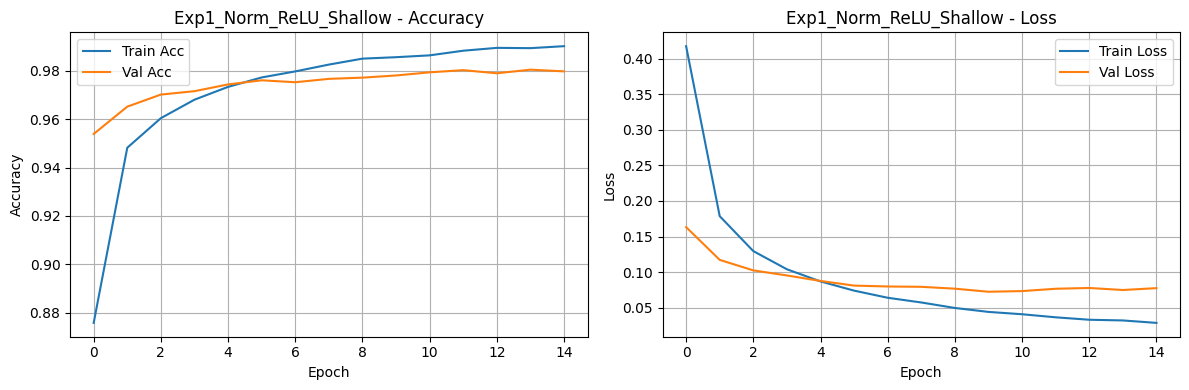

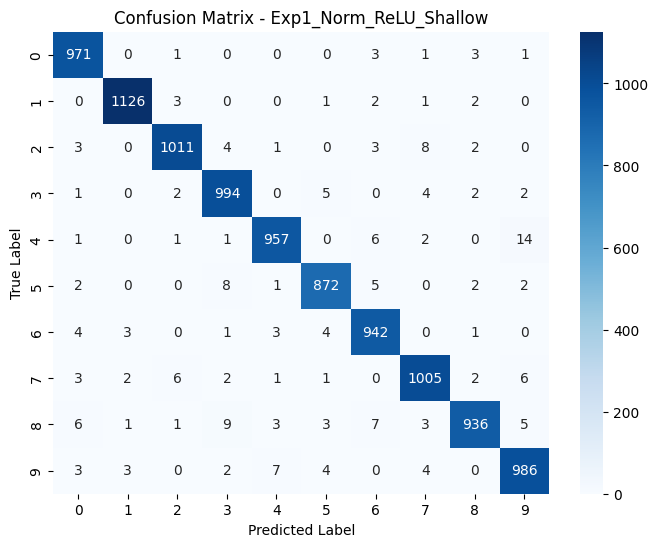

Classification Report:
              precision    recall  f1-score   support

           0     0.9769    0.9908    0.9838       980
           1     0.9921    0.9921    0.9921      1135
           2     0.9863    0.9797    0.9830      1032
           3     0.9736    0.9842    0.9788      1010
           4     0.9836    0.9745    0.9790       982
           5     0.9798    0.9776    0.9787       892
           6     0.9731    0.9833    0.9782       958
           7     0.9776    0.9776    0.9776      1028
           8     0.9853    0.9610    0.9730       974
           9     0.9705    0.9772    0.9738      1009

    accuracy                         0.9800     10000
   macro avg     0.9799    0.9798    0.9798     10000
weighted avg     0.9800    0.9800    0.9800     10000



In [6]:
best_name = df_results.iloc[0]["Eksperimen"]
best_model, best_X_test, best_hist = trained_models[best_name]
print("Model terbaik:", best_name)

# 1. Learning curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_hist.history["accuracy"], label="Train Acc")
axes[0].plot(best_hist.history["val_accuracy"], label="Val Acc")
axes[0].set_title(f"{best_name} - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(best_hist.history["loss"], label="Train Loss")
axes[1].plot(best_hist.history["val_loss"], label="Val Loss")
axes[1].set_title(f"{best_name} - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

# 2. Prediksi & Confusion Matrix
y_pred_probs = best_model.predict(best_X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))